<center>
<h1> TP-Projet d'optimisation numérique </h1>
<h1> Algorithme du lagrangien augmenté </h1>
</center>

## Implémentation

1. Implémenter l'algorithme du lagrangien augmenté, en utilisant les différentes méthodes
qui ont été vues en première partie pour la résolution de la suite de problèmes sans
contraintes (fichier `src/lagrangien_augmente.jl`). La spécification est donnée dans le fichier.
2. Vérifier que les tests ci-dessous passent.
 

In [1]:
include("../src/lagrangien_augmente.jl")
include("../test/tester_lagrangien_augmente.jl")

#
afficher = true # si true, alors affiche les résultats des algorithmes

#
tester_lagrangien_augmente(lagrangien_augmente, afficher);

Affichage des résultats des algorithmes : true



-------------------------------------------------------------------------
Résultats de : LA et newton appliqué à f1:
  * x0       = [0, 1, 1]
  * x_sol    = [0.5000042424566808, 1.2499978787716595, 0.5000042424566811]
  * f(x_sol) = 2.249961818051857
  * nb_iters = 7
  * flag     = 0
  * solution = [0.5, 1.25, 0.5]
-------------------------------------------------------------------------
Résultats de : LA et newton appliqué à f1:
  * x0       = [0.5, 1.25, 1.0]
  * x_sol    = [0.5000042424566808, 1.2499978787716595, 0.5000042424566811]
  * f(x_sol) = 2.249961818051857
  * nb_iters = 7
  * flag     = 0
  * solution = [0.5, 1.25, 0.5]
-------------------------------------------------------------------------
Résultats de : LA et newton appliqué à f2:
  * x0       = [1, 0]
  * x_sol    = [0.9072336571162266, 0.8227549044924193]
  * f(x_sol) = 0.008615707033558758
  * nb_iters = 5
  * flag     = 0
  * solution = [0.9072339605110892, 0.82275545631455]
----------------------------------------

## Interprétation

 1. Commenter les résultats obtenus, en étudiant notamment les valeurs de $\lambda_k$ et $\mu_k$ au fil des itérations.

-> L'algorithme semble traverser deux phases: Celle où $\mu$ augmente et celle où il se stabilise (respect de la contrainte) à l'inverse de $\lambda$ qui s'ajuste.


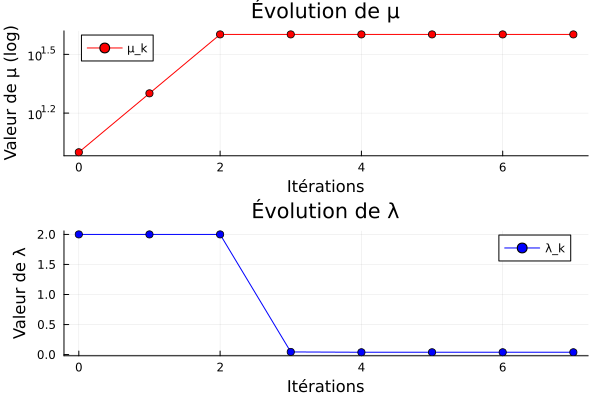

-------------------------------------------------------------------------
Résultats de : Lagrangien Augmenté (rc-gct) appliqué à f2:
  * x0       = [1, 0]
  * x_sol    = [0.9072339605032136, 0.8227554563002325]
  * f(x_sol) = 0.008615650661371363
  * nb_iters = 7
  * flag     = 0
  * solution = [0.9072339605110892, 0.82275545631455]


In [4]:
# Expérimentations numériques à faire ici.
# Vous pouvez utiliser le package Plots pour les affichages de courbes: using Plots
using Plots
include("../src/lagrangien_augmente.jl")
include("../test/fonctions_de_tests.jl")

algo_noc = "rc-gct"
x0 = pts2.x03

x_sol, f_sol, flag, nb_iters, mus, lambdas = lagrangien_augmente(
    fct2, grad_fct2, hess_fct2, 
    contrainte2, grad_contrainte2, hess_contrainte2, 
    x0, algo_noc=algo_noc)

afficher_resultats("Lagrangien Augmenté (" * algo_noc * ")", "f2", x0, x_sol, f_sol, flag, nb_iters, sol_fct2_augm)

# Tracé pour mu et lambda
l = @layout [a ; b]

p1 = plot(0:nb_iters, mus, 
    yscale=:log10, 
    label="μ_k", 
    xlabel="Itérations", 
    ylabel="Valeur de μ (log)", 
    title="Évolution de μ", 
    color=:red,
    marker=:circle)

p2 = plot(0:nb_iters, lambdas, 
    label="λ_k", 
    xlabel="Itérations", 
    ylabel="Valeur de λ", 
    title="Évolution de λ", 
    color=:blue,
    marker=:circle)

plot(p1, p2, layout=l)
display(current())


 2. Dans la méthode du lagrangien augmenté, la convergence est généralement suivie à l’aide de deux conditions: le résidu de faisabilité, qui mesure la violation de la contrainte $c(x) = 0$, et le gradient du lagrangien augmenté. Observez l’évolution de ces deux grandeurs au cours de vos expérimentations numériques. Laquelle des deux a tendance à converger plus rapidement, et pourquoi ce comportement se manifeste-t-il compte tenu de l’augmentation progressive du paramètre de pénalité $\mu_k$?


In [ ]:
# Expérimentations numériques à faire ici.
# Vous pouvez utiliser le package Plots pour les affichages de courbes: using Plots

#je n'ai plus la foi je suis au bout du rouleau


 3. Expliquez pourquoi le paramètre de pénalité $\mu_k$ augmente généralement à chaque itération externe. Que peut-il se passer s’il est augmenté trop rapidement ou, au contraire, pas suffisamment?

-> Il est augmené pour amener le solveur à satisfaire la contrainte. S'il est augmenté trop rapidement, à partir de la question suivante je devine que la hessienne du lagrangien augmenté est mal conditionnée... Mais s'il n'augmente pas suffisamment rapidement, la contrainte prendra trop de temps à être satisfaite et on perdra en efficacité.

 4. À l’aide d’un exemple numérique de votre choix, démontrez l’impact de $\mu_k$ sur le mauvais conditionnement de la hessienne du lagrangien augmenté. Comment ce phénomène influence-t-il le coût de calcul des solveurs sans contraintes utilisés?
 5. À l’aide d’un exemple de votre choix, testez l’algorithme pour différentes valeurs initiales du paramètre de pénalité $\mu_0$. Tracez la violation de contrainte $\|c(x_k)\|$ ainsi que la norme du gradient du lagrangien augmenté au fil des itérations. Discutez comment le choix de $\mu_0$ influence la vitesse de convergence et la stabilité de l’algorithme.
 6. Tracez l’évolution de $\lambda_k$ au cours des itérations externes. Converge-t-il vers une valeur significative? Que se passe-t-il si la contrainte n’est pas exactement satisfaite?
 7. Étudier l'influence du paramètre $\tau$ dans la performance de l'algorithme. Pour cela Vous réaliserez des tests numériques.
 8. Expliquez comment le choix de différents solveurs de sous-problèmes influence la convergence de la méthode du lagrangien augmenté. Une solution de haute précision du problème interne est-elle toujours nécessaire ? Pourquoi ou pourquoi pas ?

-> Cette question résume les comparatifs faits jusque-là dans chaque notebook:

L'algorithme de Newton est rapide et converge quadratiquement mais cette convergence n'est pas garantie.

Les régions de confiance avec les pas de Cauchy convergent systématiquement mais de manière ~linéaire.

Enfin, les régions de confiance avec le Gradient Conjugué Tronqué convergent bien plus rapidement que les pas de Cauchy tout en garantissant la convergence.

Non on n'a pas toujours besoin d'une solution de haute précision quand nos paramètres $\mu_k$ et $\lambda_k$ n'ont pas encore platonné comme vu précédemment.